# Artificial Intelligence in Health Care

# NB4: Sequence Modelling: ECG with a 1D-CNN and an LSTM


In the lecture we discussed different time-series tasks and the potential pitfalls in data splitting.

Here, we build one beat classifier and train it **twice**: once with a random split over
beats, once with the split the AAMI (Association for the Advancement of Medical Instrumentation) standard requires. Same model, same data, same
budget. Then we compare a 1D-CNN against an LSTM on the patient-stratified split.

**Dataset: MIT-BIH Arrhythmia.** 48 half-hour recordings from 47 subjects, every
beat annotated by cardiologists. From PhysioNet (but not PTB-XL: UE3 uses that).


---
## 0 Setup

One new package this session (**install in your conda env; do not forget to activate the env before pip install**).

```
pip install wfdb
```

`wfdb` is the reference reader for PhysioNet's waveform format. It can stream
records straight from the server, so there is nothing to download by hand.

In [1]:
import os, time
os.environ["KERAS_BACKEND"] = "torch"

import warnings
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)

GOOD, BAD, BLUE, GREY = "#4F7A24", "#B53A36", "#1F497D", "#8C8C90"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("keras", keras.__version__, "| backend", keras.backend.backend(),
      "| wfdb", wfdb.__version__)

keras 3.15.1 | backend torch | wfdb 4.3.1


---
## 1 The signal

Before any modelling, look at the data. A beat classifier that you cannot picture
is a beat classifier you cannot debug.

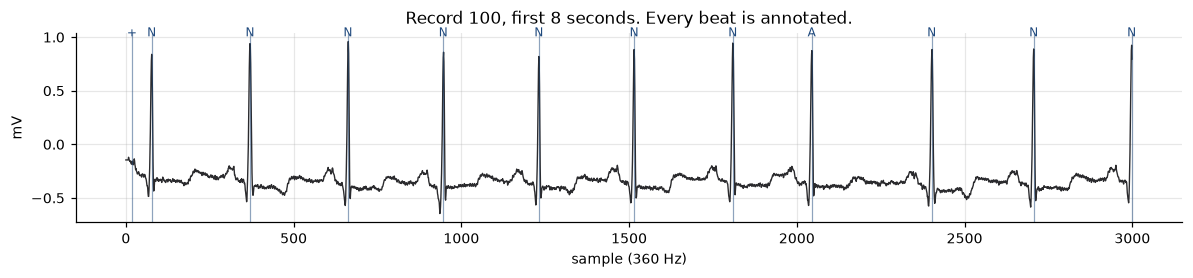

signal length : 3000 samples
sampling rate : 360 Hz
annotations   : 12 in this window


In [2]:
rec = wfdb.rdrecord("100", pn_dir="mitdb", channels=[0], sampto=3000)
ann = wfdb.rdann("100", "atr", pn_dir="mitdb", sampto=3000)

fig, ax = plt.subplots(figsize=(11, 2.6))
ax.plot(rec.p_signal[:, 0], color="#2B2B2E", lw=0.9)
for pos, sym in zip(ann.sample, ann.symbol):
    ax.axvline(pos, color=BLUE, lw=0.8, alpha=0.5)
    ax.text(pos, rec.p_signal[:, 0].max() * 1.05, sym, fontsize=8,
            ha="center", color=BLUE)
ax.set(xlabel="sample (360 Hz)", ylabel="mV",
       title="Record 100, first 8 seconds. Every beat is annotated.")
plt.tight_layout(); plt.show()

print("signal length :", rec.sig_len, "samples")
print("sampling rate :", rec.fs, "Hz")
print("annotations   :", len(ann.sample), "in this window")

The vertical lines are **cardiologist annotations**, one per beat, each carrying a
symbol. `N` is a normal beat. That is what makes MIT-BIH valuable and also what
makes it small: someone labelled every one of roughly 100,000 beats by hand.

The annotation symbols are finer-grained than anyone needs clinically, so the
**AAMI standard** groups them into five classes. We use four of them:

| AAMI class | Meaning | Symbols |
|---|---|---|
| **N** | normal or bundle branch block | `N L R e j` |
| **S** | supraventricular ectopic | `A a J S` |
| **V** | ventricular ectopic | `V E` |
| **F** | fusion of ventricular and normal | `F` |

The fifth class, `Q` (unclassifiable and paced), is dropped, as is standard. The
four **paced records** (102, 104, 107, 217) are excluded entirely: a pacemaker
changes the morphology of every beat, and no published inter-patient result
includes them.

---
## 2 From a recording to a dataset of beats

Three decisions turn a continuous signal into supervised examples. Each is a place
where something can go quietly wrong.

1. **Window.** Take a fixed number of samples around each annotated beat.
2. **Normalisation.** Per recording, **not** across the dataset. Amplitude depends
   on electrode placement and body habitus, so normalising globally lets the model
   read the patient rather than the rhythm.
3. **Keep the record identity.** We need it to perform different splits.

In [ ]:
# AAMI class mapping from symbol annotations. 
# Q (unclassifiable / paced) is dropped by convention.
# We want to create a mapping from the annotation symbols to the AAMI classes N, S, V, F.
# Therefore, we generate a flat dictionary with the following logic:

AAMI = {**{s: "N" for s in "NLRej"}, **{s: "S" for s in "AaJS"},
        **{s: "V" for s in "VE"}, "F": "F"}

# What the hell is this? Does this make sense?
print("AAMI mapping dictonary:", AAMI)
print("AAMI mapping keys:", AAMI.keys())

# Longer but better (?) understandable version of how to generate this mapping:
# 1. Define the groups according to standard AAMI medical categories
start_time = time.perf_counter()

label_mapping = {
    "NLRej": "N",  # Normal / Bundle branch block beats
    "AaJS": "S",   # Supraventricular ectopic beats
    "VE": "V",     # Ventricular ectopic beats
    "F": "F"       # Fusion beats
}

print("\nLabel mapping dictionary items:", label_mapping.items())
AAMI_ = {}
for characters, target_category in label_mapping.items():
    # item: (characters, target_category) = ('NLRej', 'N')
    # loop over each character in the string 'NLRej' and assign it to the target category 'N'
    for char in characters:
        AAMI_[char] = target_category

print("\nAAMI_ mapping dictionary:", AAMI_)


AAMI mapping dictonary: {'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N', 'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S', 'V': 'V', 'E': 'V', 'F': 'F'}
AAMI mapping keys: dict_keys(['N', 'L', 'R', 'e', 'j', 'A', 'a', 'J', 'S', 'V', 'E', 'F'])

Label mapping dictionary items: dict_items([('NLRej', 'N'), ('AaJS', 'S'), ('VE', 'V'), ('F', 'F')])

AAMI_ mapping dictionary: {'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N', 'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S', 'V': 'V', 'E': 'V', 'F': 'F'}


In [ ]:

CLASSES = ["N", "S", "V", "F"]

# De Chazal et al. (2004) (https://doi.org/10.1155/2021/9946596) 
# proposed dividing the 44 suitable records from the 
# MIT-BIH Arrhythmia Database into two equal sets of 22 patient recordings, 
# denoted as DS1 and DS2, to establish a rigorous inter-patient evaluation 
# for automated heartbeat classification. 
# This partitioning strategy prevents data leakage and evaluation bias 
# by ensuring that patient records do not overlap between the training and testing sets.

DS1 = [101, 106, 108, 109, 112, 114, 115, 116, 118, 119, 122,
       124, 201, 203, 205, 207, 208, 209, 215, 220, 223, 230]
DS2 = [100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210,
       212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234]

WIN = 180          # samples around the R peak, 0.5 s at 360 Hz)


def load_records(records):
    '''Return (beats, labels, record_id). record_id is what makes §3 possible.'''
    X, y, g = [], [], []
    for r in records:
        rec = wfdb.rdrecord(str(r), pn_dir="mitdb", channels=[0])
        ann = wfdb.rdann(str(r), "atr", pn_dir="mitdb")
        sig = rec.p_signal[:, 0].astype("float32")
        # normalize the signal to zero mean and unit variance
        sig = (sig - sig.mean()) / (sig.std() + 1e-8)      # PER RECORD not global or windowed
        for pos, sym in zip(ann.sample, ann.symbol):
            cls = AAMI.get(sym)
            if cls is None:
                continue
            # extract a window around the R peak
            a, b = pos - WIN // 2, pos + WIN // 2
            # check if the window is within the signal bounds
            if a < 0 or b > len(sig):
                continue
            # append the window, label, and record id
            X.append(sig[a:b]); y.append(cls); g.append(r)
    return np.array(X, "float32"), np.array(y), np.array(g)


t0 = time.time()
print("streaming 44 records from PhysioNet, this takes a few minutes ...")
X1, y1, g1 = load_records(DS1)
X2, y2, g2 = load_records(DS2)
# concatenate the two datasets and add a channel dimension
# we need channel dimension for keras, but wfdb returns 1D arrays, 
# so we add a new axis at the end
X = np.concatenate([X1, X2])[..., None]

# concatenate the labels and record ids
y = np.concatenate([y1, y2])
g = np.concatenate([g1, g2])
# convert labels to integer indices
yi = np.array([CLASSES.index(c) for c in y])

print(f"done in {time.time()-t0:.0f}s")
print("beats    :", len(X))
print("subjects :", len(np.unique(g)))
print("shape    :", X.shape)
print()
for i, c in enumerate(CLASSES):
    print(f"  {c}: {(yi==i).sum():>6}  ({100*(yi==i).mean():5.2f}%)")

In [ ]:
# Export the dataset to a compressed npz file for later use
#np.savez('MIT-BIH_dataset.npz', X=X, y=y, g=g, yi=yi)

# Import the dataset from the compressed npz file (instead of streaming from PhysioNet)
# Use this if you want to avoid streaming the data from PhysioNet every time you run the code.
# MIT-BIH_dataset.npz is available at Moodle
data = np.load('MIT-BIH_dataset.npz')

# Access individual arrays using the keys you defined
X = data['X']
y = data['y']
g = data['g']
yi = data['yi']

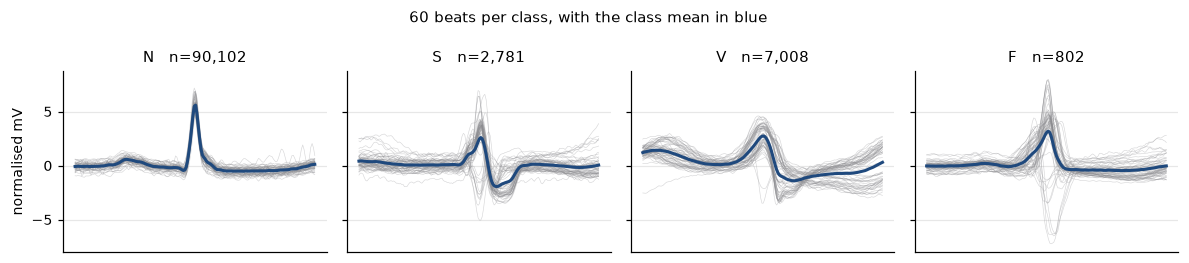

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.4), sharey=True)
for ax, (i, c) in zip(axes, enumerate(CLASSES)):
    idx = np.where(yi == i)[0][:60]
    for j in idx:
        ax.plot(X[j, :, 0], color=GREY, lw=0.4, alpha=0.35)
    ax.plot(X[idx].mean(0)[:, 0], color=BLUE, lw=2)
    ax.set_title(f"{c}   n={(yi==i).sum():,}", fontsize=10)
    ax.set_xticks([])
axes[0].set_ylabel("normalised mV")
fig.suptitle("60 beats per class, with the class mean in blue", fontsize=10)
plt.tight_layout(); plt.show()

### What do you expect?

Look at those four averages. 
We are giving the model a window around a single beat and no timing information at
all. Before running anything, predict which class the model will fail on.

The class distribution: **N is about 90 % of beats.**
Anything that reports accuracy on this data is reporting mostly N.

---
## 3 The two splits

Now the demonstration of the importance of correct data splitting.

**Split A, random over beats.** The default. `train_test_split` on 100,000 rows.

**Split B, AAMI inter-patient.** Records DS1 for training, records DS2 for testing.
No subject appears in both.

Same architecture, same epochs, same everything else.

In [7]:
idx = np.arange(len(X))
tr_rand, te_rand = train_test_split(idx, test_size=0.2, random_state=SEED,
                                    stratify=yi)
tr_grp = idx[np.isin(g, DS1)]
te_grp = idx[np.isin(g, DS2)]

print("SPLIT A, random over beats")
print(f"   train {len(tr_rand):,}   test {len(te_rand):,}")
print(f"   subjects appearing on BOTH sides: "
      f"{len(set(g[tr_rand]) & set(g[te_rand]))} of {len(np.unique(g))}")
print()
print("SPLIT B, AAMI inter-patient DS1/DS2")
print(f"   train {len(tr_grp):,}   test {len(te_grp):,}")
print(f"   subjects appearing on BOTH sides: "
      f"{len(set(g[tr_grp]) & set(g[te_grp]))} of {len(np.unique(g))}")

SPLIT A, random over beats
   train 80,554   test 20,139
   subjects appearing on BOTH sides: 44 of 44

SPLIT B, AAMI inter-patient DS1/DS2
   train 51,002   test 49,691
   subjects appearing on BOTH sides: 0 of 44


**Every single subject is on both sides of the random split.** Not a handful. All
of them. The model will see thousands of beats from a patient during training and
then be tested on more beats from that same patient.

### What do you expect, part two

1. How far does **accuracy** fall from split A to split B?
2. How far does **macro F1** fall?
3. How far does **AUROC** fall?

In [8]:
def build_cnn(n_time):
    keras.utils.set_random_seed(SEED)
    return keras.Sequential([
        layers.Input(shape=(n_time, 1)),
        layers.Conv1D(32, 7, activation="relu", padding="same"),
        layers.MaxPooling1D(2),
        layers.Conv1D(64, 5, activation="relu", padding="same"),
        layers.MaxPooling1D(2),
        layers.Conv1D(64, 3, activation="relu", padding="same"),
        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dense(len(CLASSES)),
    ], name="cnn1d")


def train_eval(model, tr, te, tag, epochs=6):
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name="acc")])
    t0 = time.time()
    model.fit(X[tr], yi[tr], epochs=epochs, batch_size=256, verbose=0)
    secs = time.time() - t0
    prob = keras.ops.softmax(model.predict(X[te], verbose=0)).numpy()
    pred = prob.argmax(1)
    out = dict(tag=tag,
               acc=accuracy_score(yi[te], pred),
               f1=f1_score(yi[te], pred, average="macro"),
               auc=roc_auc_score(yi[te], prob, multi_class="ovr", average="macro"),
               params=model.count_params(), secs=secs,
               cm=confusion_matrix(yi[te], pred), pred=pred, te=te)
    print(f"{tag:<26} accuracy {out['acc']:.4f}   macro F1 {out['f1']:.4f}   "
          f"macro AUROC {out['auc']:.4f}   {secs:.0f}s")
    return out


res_rand = train_eval(build_cnn(WIN), tr_rand, te_rand, "A: random beat split")
res_grp = train_eval(build_cnn(WIN), tr_grp, te_grp, "B: inter-patient (AAMI)")

A: random beat split       accuracy 0.9651   macro F1 0.6116   macro AUROC 0.9283   76s
B: inter-patient (AAMI)    accuracy 0.9368   macro F1 0.4504   macro AUROC 0.8381   47s


In [9]:
base = (yi[te_grp] == 0).mean()
print(f"{'':<14}{'accuracy':>11}{'macro F1':>11}{'macro AUROC':>14}")
print("-" * 50)
for r in (res_rand, res_grp):
    print(f"{r['tag'][:12]:<14}{r['acc']:>11.4f}{r['f1']:>11.4f}{r['auc']:>14.4f}")
print("-" * 50)
print(f"{'change':<14}{res_grp['acc']-res_rand['acc']:>+11.4f}"
      f"{res_grp['f1']-res_rand['f1']:>+11.4f}"
      f"{res_grp['auc']-res_rand['auc']:>+14.4f}")
print()
print(f"always answering 'N' on the DS2 test set scores {base:.4f}")
print(f"the inter-patient model scores                        {res_grp['acc']:.4f}")
print(f"benefit over doing nothing                    {res_grp['acc']-base:+.4f}")

                 accuracy   macro F1   macro AUROC
--------------------------------------------------
A: random be       0.9651     0.6116        0.9283
B: inter-pat       0.9368     0.4504        0.8381
--------------------------------------------------
change            -0.0283    -0.1612       -0.0903

always answering 'N' on the DS2 test set scores 0.8904
the inter-patient model scores                        0.9368
benefit over doing nothing                    +0.0464


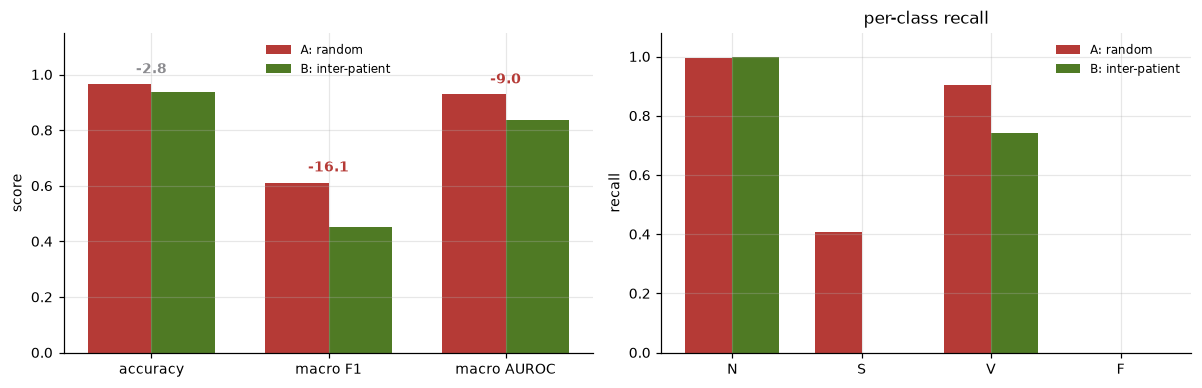

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

ax = axes[0]
names = ["accuracy", "macro F1", "macro AUROC"]
a = [res_rand["acc"], res_rand["f1"], res_rand["auc"]]
b = [res_grp["acc"], res_grp["f1"], res_grp["auc"]]
xs = np.arange(3); w = 0.36
ax.bar(xs - w/2, a, w, color=BAD, label="A: random")
ax.bar(xs + w/2, b, w, color=GOOD, label="B: inter-patient")
for i, (u, v) in enumerate(zip(a, b)):
    ax.text(i, max(u, v) + 0.04, f"{(v-u)*100:+.1f}", ha="center",
            fontweight="bold", color=GREY if abs(v-u) < 0.05 else BAD)
#ax.axhline(base, color=GREY, ls="--", lw=1.2)
ax.set(xticks=xs, xticklabels=names, ylim=(0, 1.15), ylabel="score")
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
rec_a = res_rand["cm"].diagonal() / res_rand["cm"].sum(1).clip(1)
rec_b = res_grp["cm"].diagonal() / res_grp["cm"].sum(1).clip(1)
xs = np.arange(len(CLASSES))
ax.bar(xs - w/2, rec_a, w, color=BAD, label="A: random")
ax.bar(xs + w/2, rec_b, w, color=GOOD, label="B: inter-patient")
ax.set(xticks=xs, xticklabels=CLASSES, ylim=(0, 1.08), ylabel="recall",
       title="per-class recall")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### Read this carefully, because it shows why correct data splitting is important

**Accuracy barely moved.** Someone who reported only accuracy would conclude
that the split is a technicality and move on.

**But: macro F1 drops**, and the per-class chart shows where it went: the
class that collapses is **S**, the supraventricular beat. 
That is 2.8 % of the data, so accuracy cannot see it.

**Compare the accuracy against always answering "N".** The gap is small.
This is the same lesson as in previous lectures with the prevalence issue, arriving from a
different direction.

Two things were wrong at once, and each hid the other:

- the **split** let the model memorise patients
- the **metric** was insensitive to the class where that mattered

Fix only one and you still get a misleading result.

In [11]:
print("SPLIT B, the honest one, in full:")
print(classification_report(yi[te_grp], res_grp["pred"],
                            target_names=CLASSES, digits=3, zero_division=0))

SPLIT B, the honest one, in full:
              precision    recall  f1-score   support

           N      0.936     0.998     0.966     44246
           S      0.000     0.000     0.000      1837
           V      0.957     0.742     0.836      3220
           F      0.000     0.000     0.000       388

    accuracy                          0.937     49691
   macro avg      0.473     0.435     0.450     49691
weighted avg      0.895     0.937     0.914     49691



---
## 4 1D-CNN against LSTM

From here on we use **only** the inter-patient split. Anything else would be
measuring the wrong thing.

The lecture argued that a 1D-CNN is often as good as a recurrent model on short
physiological windows, trains far faster, and has no vanishing-gradient problem.
Here we investigate this.

**One practical note.** A 180-sample window is a long sequence for an LSTM. We
reduce the length first with a strided convolution, which is standard practice and
is exactly the kind of design decision UE3 asks you to declare.

In [12]:
def build_lstm(n_time):
    keras.utils.set_random_seed(SEED)
    return keras.Sequential([
        layers.Input(shape=(n_time, 1)),
        # shorten the sequence before the recurrent layer sees it
        layers.Conv1D(32, 7, strides=3, activation="relu", padding="same"),
        layers.LSTM(64),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dense(len(CLASSES)),
    ], name="lstm")


res_lstm = train_eval(build_lstm(WIN), tr_grp, te_grp,
                      "LSTM (inter-patient)", epochs=6)

LSTM (inter-patient)       accuracy 0.8906   macro F1 0.4056   macro AUROC 0.8100   383s


In [13]:
print(f"{'model':<26}{'accuracy':>10}{'macro F1':>11}{'AUROC':>9}"
      f"{'params':>10}{'train s':>9}")
print("-" * 75)
for r in (res_grp, res_lstm):
    print(f"{r['tag']:<26}{r['acc']:>10.4f}{r['f1']:>11.4f}{r['auc']:>9.4f}"
          f"{r['params']:>10,}{r['secs']:>9.0f}")

model                       accuracy   macro F1    AUROC    params  train s
---------------------------------------------------------------------------
B: inter-patient (AAMI)       0.9368     0.4504   0.8381    27,332       47
LSTM (inter-patient)          0.8906     0.4056   0.8100    29,508      383


### Let's interprete the results

The 1D-CNN performs best.

It is **more accurate**, has a **better macro F1**, a **better macro AUROC**, uses
about the same number of parameters, and trains faster. 

Now look at the LSTM's accuracy next to the number from §3: **0.8906 against a
majority-class baseline of 0.8904.** Within a rounding error of always answering
"normal". On this task, with this budget, the recurrent model learned almost
nothing that a constant prediction does not already give you.

Three cautions before you generalise it:

- **A fairer LSTM might do better.** More epochs, a bidirectional layer, a
  different sequence reduction. We fixed the budget deliberately so the comparison
  is honest, and a fixed budget is itself a choice that favours the faster model.
- **The window is 0.5 seconds.** Recurrence earns its keep on long sequences with
  real long-range structure. Half a second of one beat is close to the worst case
  for it and close to the best case for a convolution.
- **Neither model can detect S or F at all.** Look again at the classification
  report above. The architecture comparison is happening on top of a model that
  fails completely on two of four classes, and the more interesting question is why
  neither can see them (not the discussion about LSTM vs. CNN). A single-beat window carries no timing information, and
  timing is most of what makes a supraventricular beat abnormal.


# Artificial Intelligence in Health Care - Exercise 3
## Diagnostic Classification from 12-Lead ECG

Mitglieder: Elbischger Selina, Krauss Marco  
Jahrgang: EHT25

Ziel dieser Übung ist es ein RNN mit einem 1D-CNN für die Verarbeitung von einem 12 Knala EKG Signal zu vergleichen.